# Módulo 1: Fundamentos, Espacios de Color y Mejoramiento Digital

**Objetivo.** Comprender la representación matricial de imágenes $F(x,y) = I$, evaluar la calidad espacial y cuántica, reducir ruido y mejorar el contraste tanto en el dominio espacial como frecuencial.

**Datos.** Se trabaja sobre un frame representativo de un registro del reflejo fotomotor. El video a utilizar se define en `config.py` mediante la variable `VIDEO_PATH`.

## 1 Carga, Muestreo y Espacios de Color

In [46]:
# Importación de librerías
import sys
sys.path.append("..")

import cv2
import matplotlib.pyplot as plt
from config import VIDEO_PATH
import numpy as np

from skimage.filters import roberts, prewitt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import pandas as pd

Frames totales: 909 | FPS: 29.5 | Duración: 30.8 s


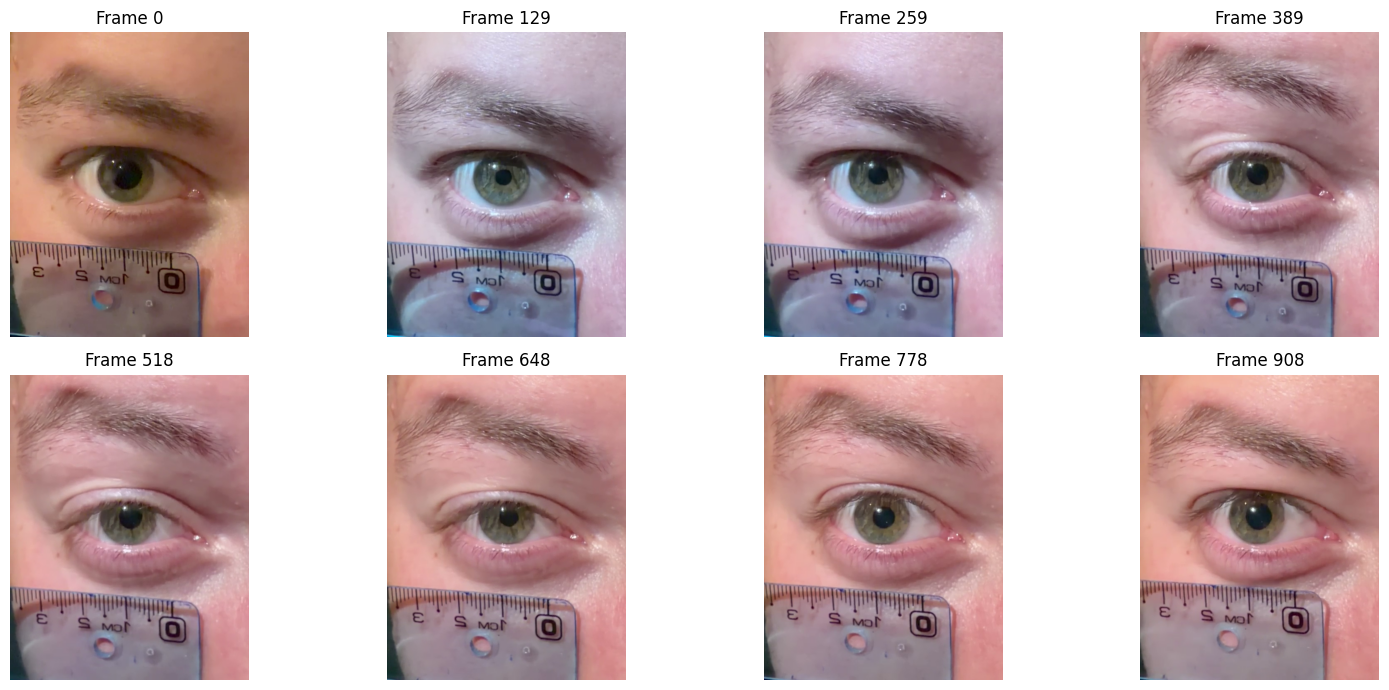

In [ ]:
# Cargamos el video y obtenemos información básica
cap = cv2.VideoCapture(str(VIDEO_PATH))
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
print(f"Frames totales: {n_frames} | FPS: {fps:.1f} | Duración: {n_frames/fps:.1f} s")

# Mostramos 8 frames repartidos a lo largo del video
indices = [int(i * (n_frames - 1) / 7) for i in range(8)]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, idx in zip(axes.flat, indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {idx}")
    ax.axis("off")
plt.tight_layout()
plt.show()
cap.release()

### Selección del frame de trabajo y ROI

Se visualizaron varios frames distribuidos a lo largo del video y ahora se elige uno representativo: ojo abierto, en foco y con buen contraste entre pupila e iris.

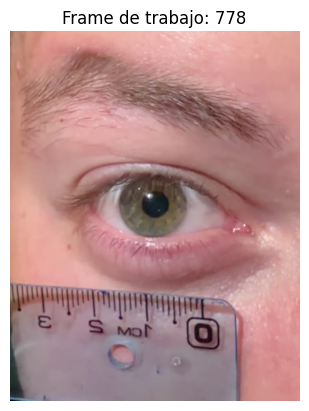

In [2]:
FRAME_IDX = 778

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"Frame de trabajo: {FRAME_IDX}")
plt.axis("off")
plt.show()

### Definición de la Región de Interés (ROI)

Se recorta una región centrada en el ojo para concentrar el análisis en la pupila y el iris, descartando párpados, piel y fondo.

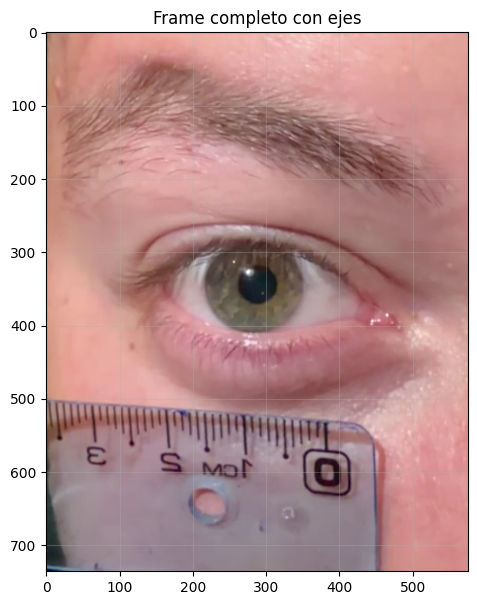

In [3]:
# Pasamos a RGB una sola vez y usamos esta versión de acá en adelante
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(frame_rgb)
plt.title("Frame completo con ejes")
plt.grid(alpha=0.3)
plt.show()

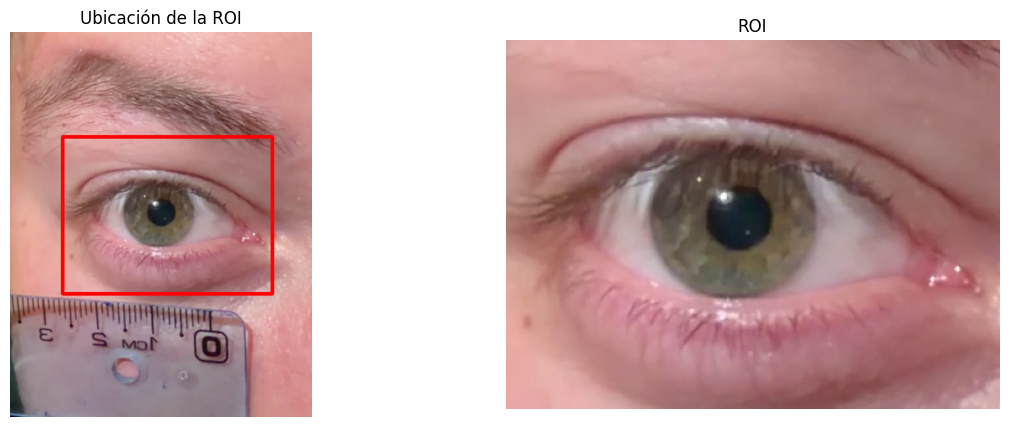

In [19]:
# ← Ajustar según tu imagen: esquina superior izquierda (x, y), ancho w y alto h
x, y, w, h = 100, 200, 400, 300

roi = frame_rgb[y:y+h, x:x+w]

# Dibujamos el rectángulo sobre una copia para verificar
vis = frame_rgb.copy()
cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(vis)
axes[0].set_title("Ubicación de la ROI")
axes[1].imshow(roi)
axes[1].set_title("ROI")
for ax in axes:
    ax.axis("off")
plt.show()

### Dimensiones y profundidad de bits

In [20]:
def info_imagen(img, nombre):
    alto, ancho = img.shape[:2]
    canales = img.shape[2] if img.ndim == 3 else 1
    bits_canal = img.dtype.itemsize * 8
    print(f"--- {nombre} ---")
    print(f"Dimensiones (Ancho x Alto): {ancho} x {alto} px")
    print(f"Canales: {canales}")
    print(f"Tipo de dato: {img.dtype} → {bits_canal} bits por canal "
          f"({2**bits_canal} niveles), {bits_canal * canales} bits por píxel")
    print(f"Rango de valores: [{img.min()}, {img.max()}]\n")

info_imagen(frame_rgb, "Frame completo")
info_imagen(roi, "ROI")

--- Frame completo ---
Dimensiones (Ancho x Alto): 576 x 736 px
Canales: 3
Tipo de dato: uint8 → 8 bits por canal (256 niveles), 24 bits por píxel
Rango de valores: [0, 255]

--- ROI ---
Dimensiones (Ancho x Alto): 400 x 300 px
Canales: 3
Tipo de dato: uint8 → 8 bits por canal (256 niveles), 24 bits por píxel
Rango de valores: [11, 255]



### Resolución espacial: submuestreo

Se reduce la resolución de la ROI al 50%, 25% y 5% de la original, tomando 1 de cada *k* píxeles. 

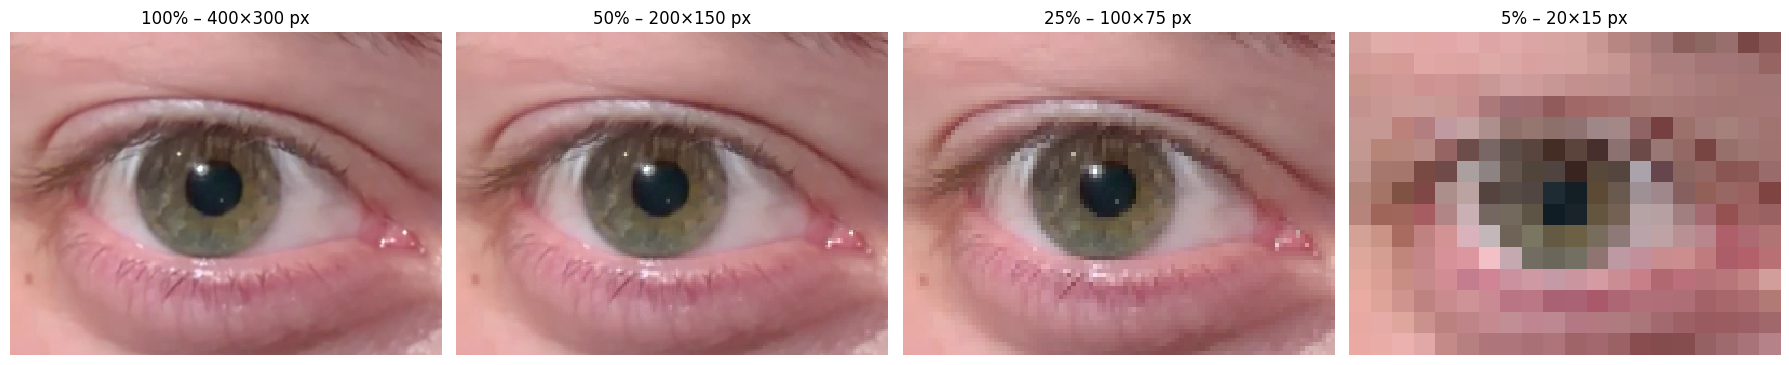

In [21]:
factores = [1, 2, 4, 20]   # 1 de cada k píxeles: 100%, 50%, 25%, 5%

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, factores):
    sub = roi[::k, ::k] #tomar una de cada k filas y una de cada k columnas
    ax.imshow(sub, interpolation="nearest")
    ax.set_title(f"{100 // k}% – {sub.shape[1]}×{sub.shape[0]} px")
    ax.axis("off")

plt.tight_layout()
plt.show()


Al 50% (225×140 px) la imagen es prácticamente indistinguible de la original: el borde de la pupila, la textura del iris, el reflejo corneal y las pestañas se siguen viendo con claridad.

Al 25% (113×70 px) se empieza a notar la pérdida de definición. La imagen se ve más borrosa, y se pierden los detalles más finos de la textura del iris. Sin embargo, la pupila, su borde y el reflejo siguen siendo identificables.

Al 5% (23×14 px) la imagen queda completamente pixelada. Solo se reconoce la forma general del ojo: la pupila aparece como un bloque oscuro de pocos píxeles, sin un borde definido, y desaparecen la textura del iris, las pestañas y el reflejo.

### Cuantización: profundidad de bits

Se reduce la cuantización de 8 bits (256 niveles) a 4 bits (16 niveles) y 2 bits (4 niveles) por canal, en la imagen color y en escala de grises.

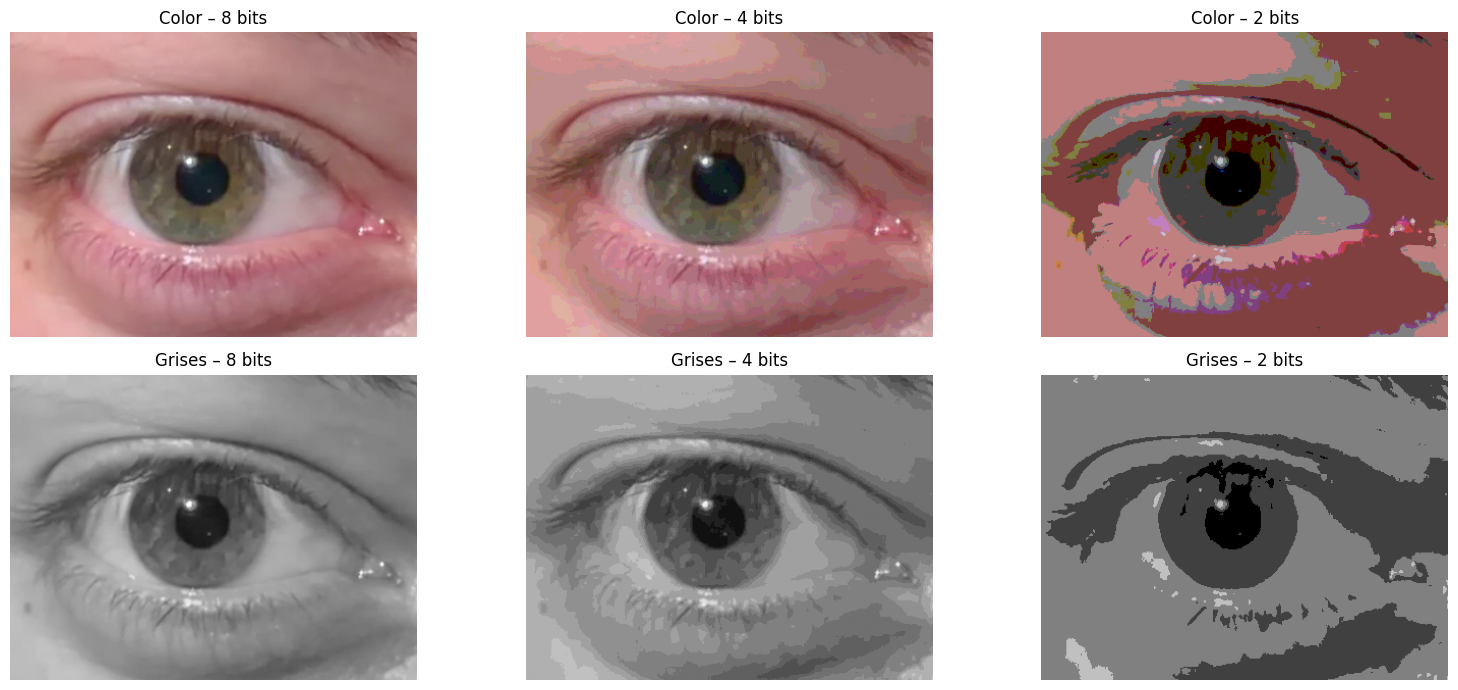

In [22]:
# Función que reduce la cantidad de niveles de intensidad de una imagen
def cuantizar(img, bits):
    niveles = 2 ** bits  #cantidad de niveles que queremos tener
    paso = 256 // niveles #tamaño de cada intervalo
    return (img // paso) * paso #dice en qué intervalo cae cada píxel. Todos los píxeles de un mismo intervalo quedan con el mismo valor

# Versión en escala de grises de la ROI
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY) #pasa de 3 canales (R, G, B) a 1 solo canal de intensidad

# Figura 
fig, axes = plt.subplots(2, 3, figsize=(16, 7))

# Recorremos las tres profundidades de bits
# j es el número de columna (0, 1, 2) y b es la cantidad de bits (8, 4, 2)
for j, b in enumerate([8, 4, 2]):
    axes[0, j].imshow(cuantizar(roi, b))
    axes[0, j].set_title(f"Color – {b} bits")
    axes[1, j].imshow(cuantizar(roi_gris, b), cmap="gray", vmin=0, vmax=255)
    axes[1, j].set_title(f"Grises – {b} bits")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Espacios de color

Se separa la ROI en sus tres canales R, G y B, y se visualiza cada uno en escala de grises. Luego se convierte la imagen de RGB a HSV y se grafican sus componentes H (matiz), S (saturación) y V (valor).

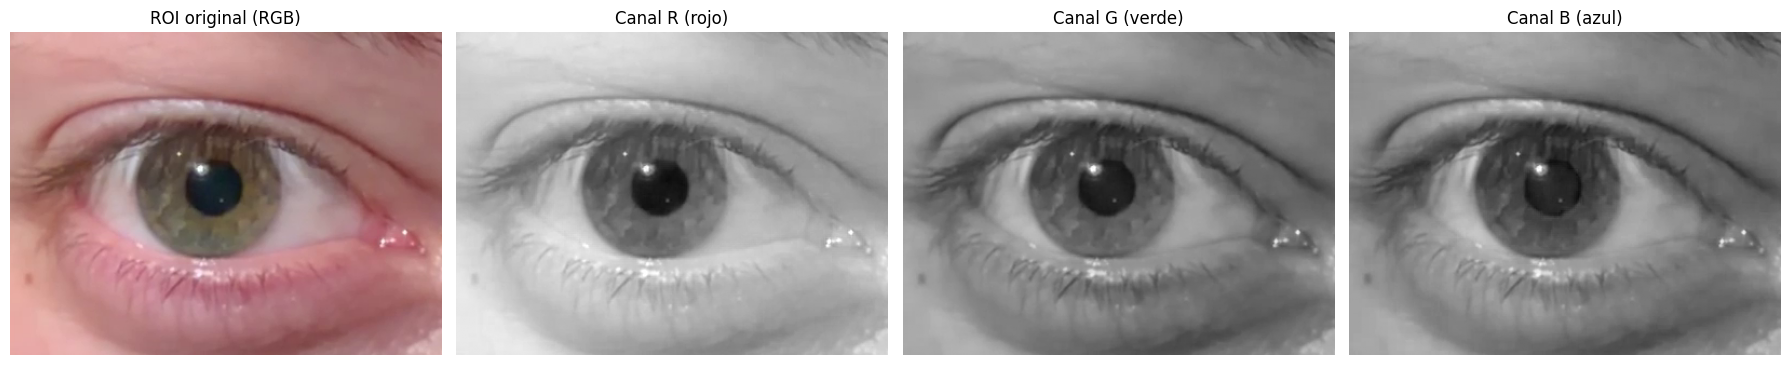

In [23]:
# Separación de la ROI en sus tres canales R, G y B
R = roi[:, :, 0]   # todas las filas, todas las columnas, canal 0
G = roi[:, :, 1]
B = roi[:, :, 2]

# Cada canal es ahora una matriz de alto × ancho (2D)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Imagen original como referencia
axes[0].imshow(roi)
axes[0].set_title("ROI original (RGB)")

# Los tres canales, cada uno en escala de grises
for ax, canal, nombre in zip(axes[1:], [R, G, B], ["R (rojo)", "G (verde)", "B (azul)"]):
    ax.imshow(canal, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Canal {nombre}")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Para leer las imágenes: en cada canal, blanco significa “mucho de ese color” y negro significa “nada de ese color”.

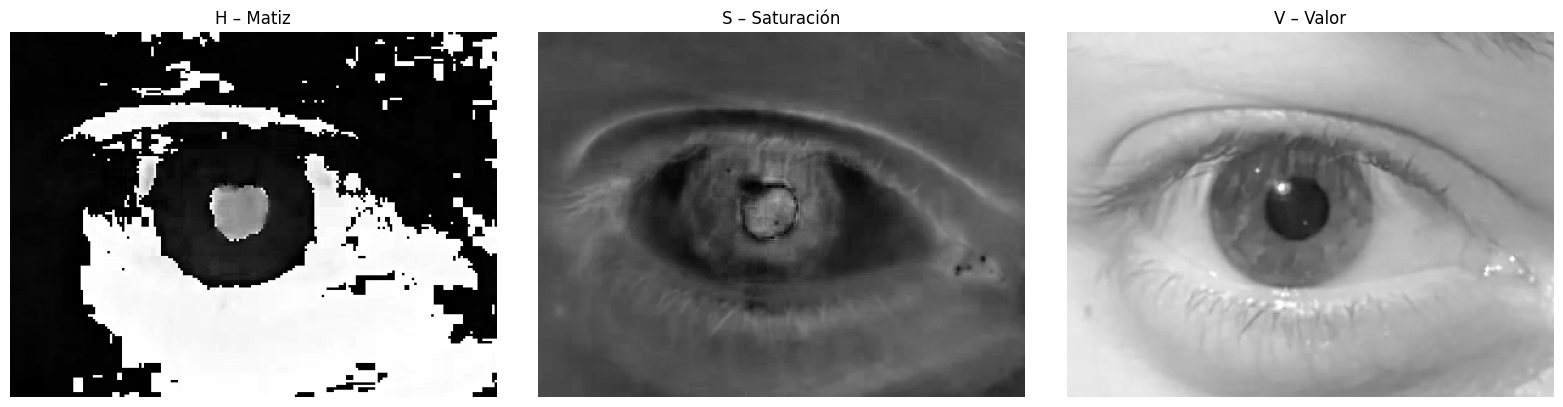

In [24]:
# Conversión de RGB a HSV

# HSV separa la información de color:
#   H (Hue / Matiz): qué color es (rojo, verde, azul...). Va de 0 a 179
#   S (Saturation): qué tan puro o intenso es el color. Va de 0 a 255
#   V (Value / Valor): qué tan claro u oscuro es. Va de 0 a 255

roi_hsv = cv2.cvtColor(roi, cv2.COLOR_RGB2HSV)

# Separamos los tres componentes, igual que con RGB
H = roi_hsv[:, :, 0]
S = roi_hsv[:, :, 1]
V = roi_hsv[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].imshow(H, cmap="gray", vmin=0, vmax=179)
axes[0].set_title("H – Matiz")

axes[1].imshow(S, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("S – Saturación")

axes[2].imshow(V, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("V – Valor")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2 Calidad, transformaciones de intensidad y filtrado espacial

### Histograma, brillo y contraste
Primero convertimos la ROI a escala de grises. Después aumentamos el brillo sumando 50 y el contraste multiplicando por 1,5.

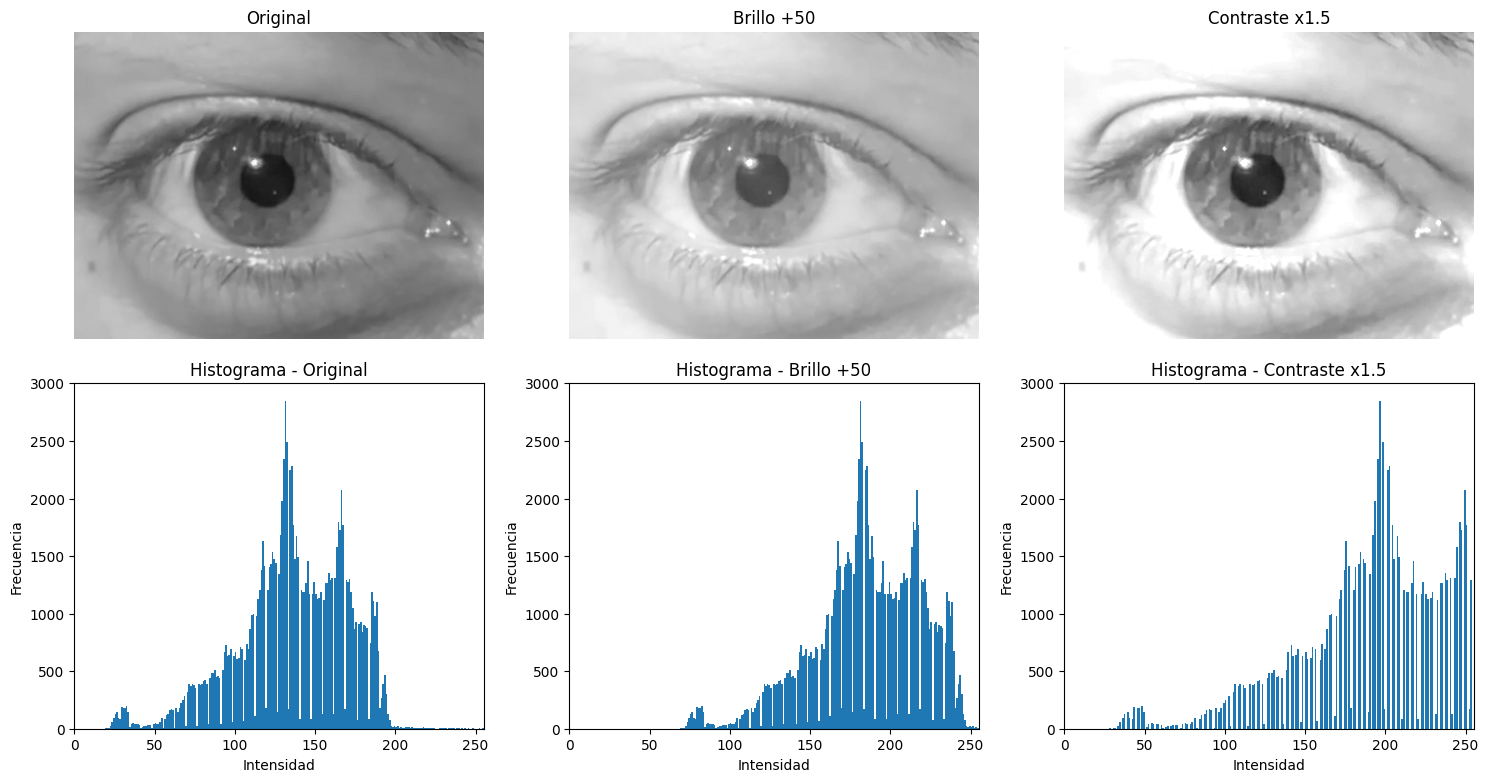

In [29]:
# Convertir ROI a escala de grises
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

# Modificar brillo y contraste
brillo = np.clip(
    roi_gris.astype(np.float32) + 50, 0, 255
).astype(np.uint8)

contraste = np.clip(
    roi_gris.astype(np.float32) * 1.5, 0, 255
).astype(np.uint8)

imagenes = [roi_gris, brillo, contraste]
titulos = ["Original", "Brillo +50", "Contraste x1.5"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (img, titulo) in enumerate(zip(imagenes, titulos)):
    axes[0, i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(titulo)
    axes[0, i].axis("off")

    axes[1, i].hist(img.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_title(f"Histograma - {titulo}")
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_ylim(0, 3000)
    axes[1, i].set_xlabel("Intensidad")
    axes[1, i].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

El incremento del brillo (+50) produjo un desplazamiento del histograma hacia intensidades mayores, conservando aproximadamente su distribución original. Sin embargo, disminuyó la diferencia visual entre la pupila y el iris.

Por otro lado, la multiplicación de las intensidades por un factor de 1,5 generó una expansión del histograma hacia valores elevados, provocando saturación en 255 y pérdida de información en las regiones más luminosas.

Para el análisis pupilar, resulta importante preservar la diferenciación entre pupila e iris sin introducir saturación excesiva, ya que esto podría afectar las etapas posteriores de detección de bordes y segmentación.

### Escalado por Rango de Interés

La idea es seleccionar un intervalo de intensidades $[f_1,f_2]$ y expandirlo al rango completo $[0,255]$, para mejorar la diferenciación entre la pupila y el iris.

Aplicamos la transformación:


$$g(x,y)=
\begin{cases}
0 & f(x,y)\leq f_1\\
\frac{255}{f_2-f_1}(f(x,y)-f_1) & f_1<f(x,y)<f_2\\
255 & f(x,y)\geq f_2
\end{cases}$$


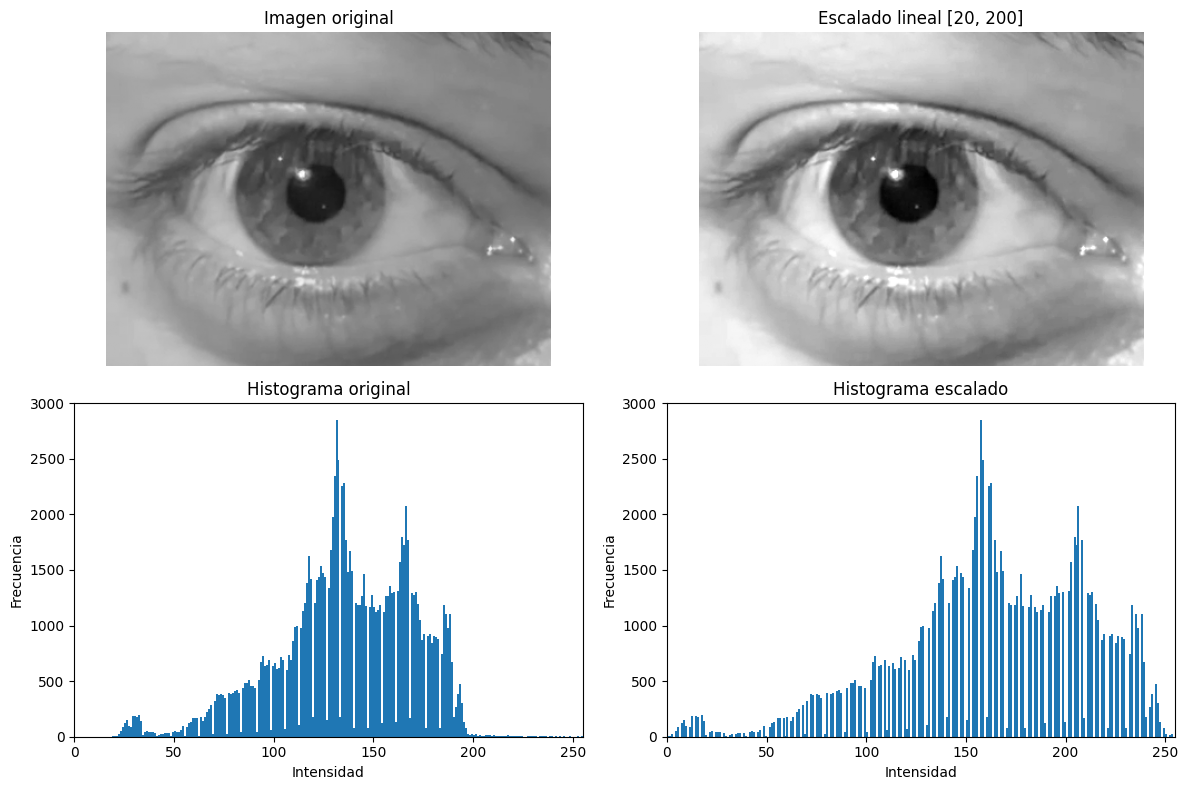

In [32]:
# Seleccionamos el intervalo de intensidades
# Ajustable según el histograma original
f1 = 20
f2 = 200

# Aplicamos la transformación lineal
escalada = np.clip(
    (roi_gris.astype(np.float32) - f1) * 255 / (f2 - f1),
    0, 255
).astype(np.uint8)

# Comparación visual e histogramas
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Imagen original")

axes[0, 1].imshow(escalada, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title(f"Escalado lineal [{f1}, {f2}]")

axes[1, 0].hist(roi_gris.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Histograma original")

axes[1, 1].hist(escalada.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Histograma escalado")

for ax in axes[0]:
    ax.axis("off")

for ax in axes[1]:
    ax.set_xlim(0, 255)
    ax.set_ylim(0, 3000)
    ax.set_xlabel("Intensidad")
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

Se evaluaron dos intervalos de intensidad para el escalado lineal: $[30,150]$ y $[20,200]$.

El primer intervalo produjo un aumento pronunciado del contraste entre la pupila y el iris, pero generó una saturación considerable de las regiones más luminosas, provocando pérdida de información.

Al ampliar el intervalo a $[20,200]$, se obtuvo una distribución de intensidades más equilibrada, conservando mayor detalle. Por lo tanto, se seleccionó este último como alternativa más adecuada para preservar las características de la imagen y facilitar su posterior procesamiento.

### Ecualización global y CLAHE

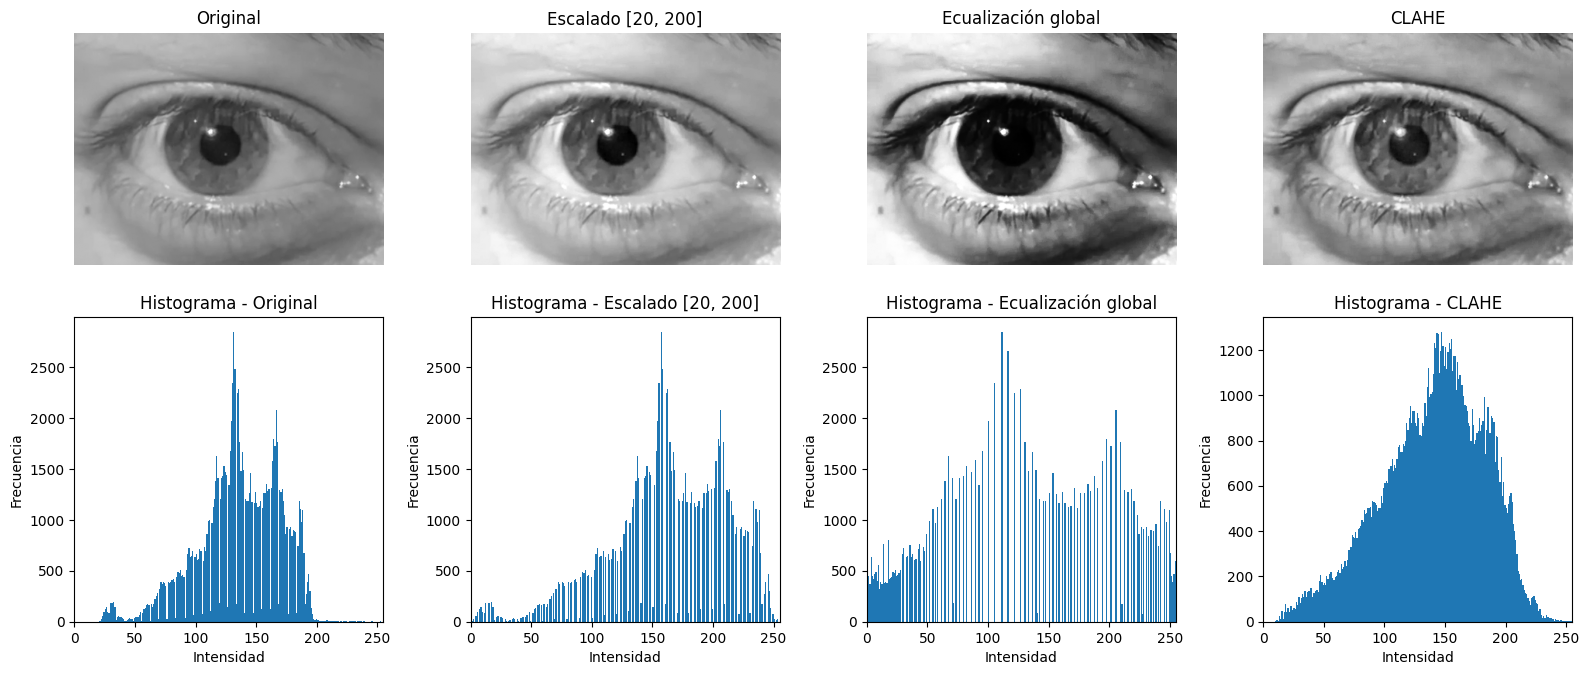

In [33]:
# Ecualización global
ecualizada = cv2.equalizeHist(roi_gris)

# Ecualización adaptativa local (CLAHE)
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

local = clahe.apply(roi_gris)

# Comparación
imagenes = [roi_gris, escalada, ecualizada, local]
titulos = [
    "Original",
    "Escalado [20, 200]",
    "Ecualización global",
    "CLAHE"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, (img, titulo) in enumerate(zip(imagenes, titulos)):
    axes[0, i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(titulo)
    axes[0, i].axis("off")

    axes[1, i].hist(
        img.ravel(),
        bins=256,
        range=(0, 256)
    )
    axes[1, i].set_title(f"Histograma - {titulo}")
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_xlabel("Intensidad")
    axes[1, i].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

Se compararon tres técnicas de mejoramiento de contraste: escalado lineal, ecualización global y ecualización adaptativa limitada por contraste (CLAHE).

El escalado lineal permitió aumentar moderadamente el contraste, conservando gran parte de las características originales. La ecualización global produjo una redistribución más amplia de intensidades, incrementando significativamente el contraste, pero generando un oscurecimiento excesivo en determinadas regiones del iris y los párpados.

Por su parte, CLAHE permitió resaltar estructuras locales del iris y mejorar la definición de los bordes sin producir cambios tan pronunciados en la luminosidad global, permitinendo identificar los detalles en varias zonas.

A partir de la inspección visual, CLAHE presentó el resultado más equilibrado para el mejoramiento de la imagen. 

### Análisis de ruido y filtrado espacial

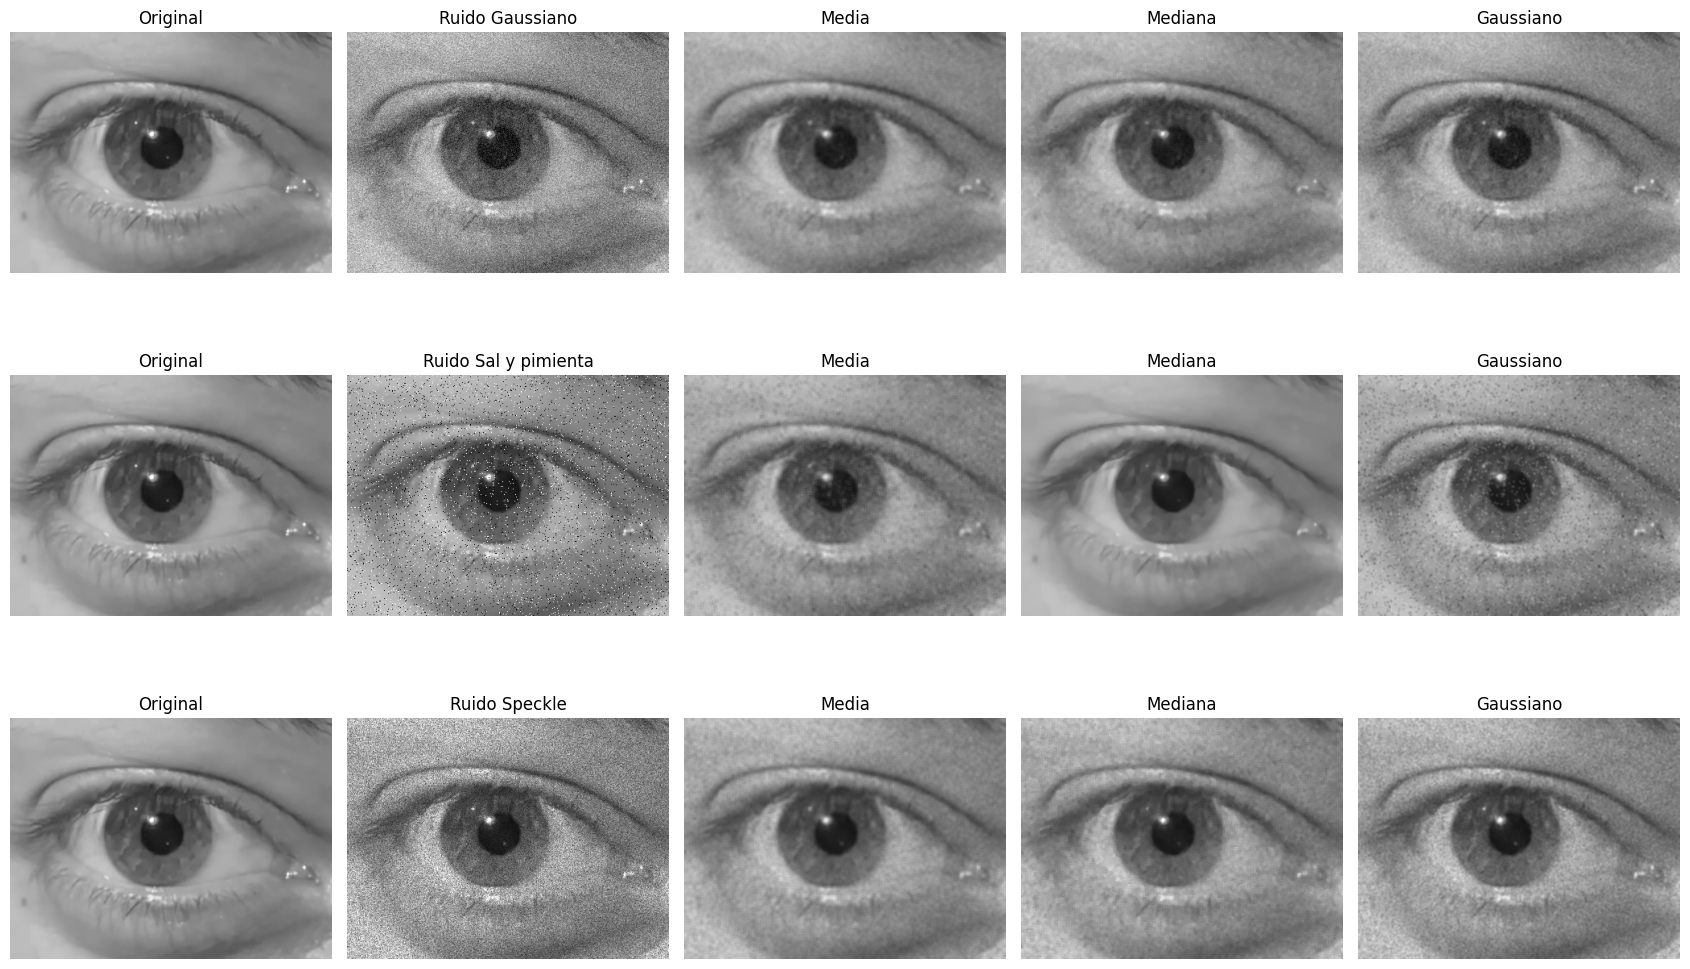

In [34]:
rng = np.random.default_rng(42)
base = roi_gris.astype(np.float32)

# Ruido gaussiano (aditivo)
ruido_gauss = np.clip(
    base + rng.normal(0, 20, base.shape),
    0, 255
).astype(np.uint8)

# Ruido impulsivo (sal y pimienta)
ruido_sp = roi_gris.copy()
prob = rng.random(base.shape)

ruido_sp[prob < 0.025] = 0
ruido_sp[(prob >= 0.025) & (prob < 0.05)] = 255

# Ruido speckle (multiplicativo)
ruido_speckle = np.clip(
    base * (1 + rng.normal(0, 0.18, base.shape)),
    0, 255
).astype(np.uint8)

ruidos = {
    "Gaussiano": ruido_gauss,
    "Sal y pimienta": ruido_sp,
    "Speckle": ruido_speckle
}

# Filtros espaciales
filtros = {
    "Media": lambda img: cv2.blur(img, (5, 5)),
    "Mediana": lambda img: cv2.medianBlur(img, 5),
    "Gaussiano": lambda img: cv2.GaussianBlur(
        img, (5, 5), 1
    )
}

# Comparación visual
fig, axes = plt.subplots(3, 5, figsize=(17, 11))

for i, (nombre, imagen) in enumerate(ruidos.items()):

    resultados = [
        ("Original", roi_gris),
        (f"Ruido {nombre}", imagen)
    ]

    resultados += [
        (nombre_filtro, funcion(imagen))
        for nombre_filtro, funcion in filtros.items()
    ]

    for j, (titulo, img) in enumerate(resultados):
        axes[i, j].imshow(
            img, cmap="gray", vmin=0, vmax=255
        )
        axes[i, j].set_title(titulo)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

Se simularon tres tipos de ruido sobre la ROI pupilar: gaussiano, impulsivo (sal y pimienta) y speckle. Posteriormente, se aplicaron filtros espaciales de media, mediana y Gaussiano para evaluar su capacidad de reducción de ruido y preservación de estructuras.

Para el ruido gaussiano, los tres filtros lograron atenuar las fluctuaciones de intensidad, aunque el filtro de media produjo un suavizado más pronunciado de los contornos. En el caso del ruido sal y pimienta, el filtro de mediana presentó el mejor desempeño visual, eliminando gran parte de los píxeles impulsivos y preservando la geometría pupilar.

Para el ruido speckle, los filtros de media y mediana redujeron considerablemente la textura granulada, mientras que el filtro Gaussiano conservó una mayor cantidad de ruido residual con los parámetros utilizados.

En términos generales, el filtro de mediana presentó un equilibrio favorable entre reducción de ruido y conservación del contorno pupilar. Sin embargo, esta observación debe complementarse con métricas cuantitativas para determinar su desempeño frente a los distintos tipos de ruido.

## 3. Detección de Bordes y Dominio Frecuencial 

Los bordes corresponden a regiones donde se producen cambios bruscos de intensidad. En nuestro caso, nos interesa principalmente detectar la transición entre la pupila y el iris.

### Comparación de los cinco operadores

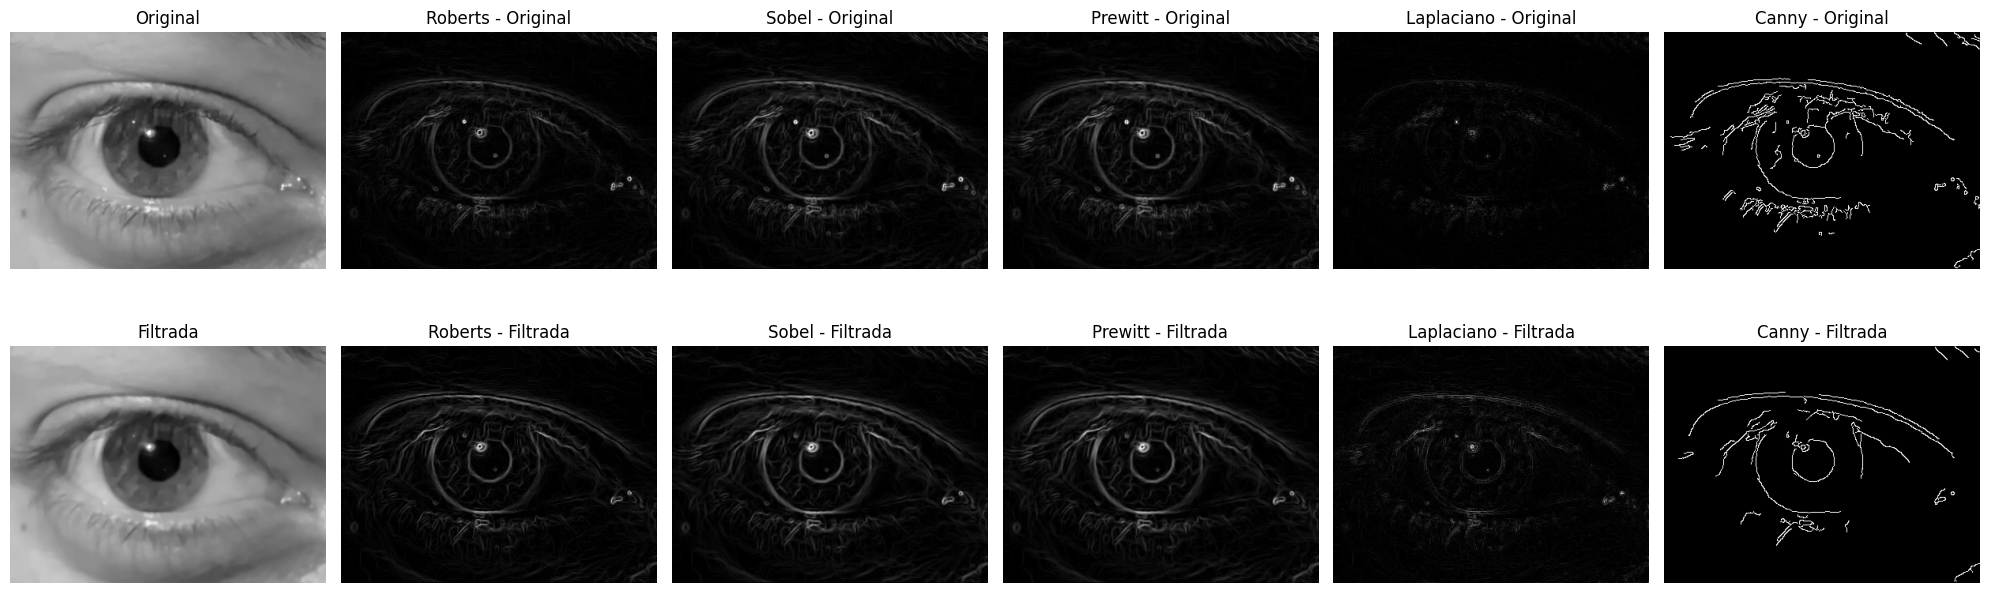

In [37]:
# Imagen original en escala de grises
original = roi_gris.copy()

# Imagen filtrada con mediana
filtrada = cv2.medianBlur(original, 5)

def detectar_bordes(img):

    # Normalización para operadores de skimage
    img_float = img.astype(np.float32) / 255.0

    # Roberts
    bordes_roberts = roberts(img_float)

    # Sobel: derivadas en X e Y
    sobel_x = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    bordes_sobel = cv2.magnitude(sobel_x, sobel_y)

    # Prewitt
    bordes_prewitt = prewitt(img_float)

    # Laplaciano
    bordes_laplaciano = np.abs(
        cv2.Laplacian(img, cv2.CV_32F, ksize=3)
    )

    # Canny
    bordes_canny = cv2.Canny(
        img, threshold1=50, threshold2=120
    )

    return {
        "Roberts": bordes_roberts,
        "Sobel": bordes_sobel,
        "Prewitt": bordes_prewitt,
        "Laplaciano": bordes_laplaciano,
        "Canny": bordes_canny
    }


# Aplicamos los operadores a ambas imágenes
bordes_original = detectar_bordes(original)
bordes_filtrada = detectar_bordes(filtrada)

# Visualización
fig, axes = plt.subplots(2, 6, figsize=(20, 7))

imagenes = [
    ("Original", original, bordes_original),
    ("Filtrada", filtrada, bordes_filtrada)
]

for i, (nombre, img, resultados) in enumerate(imagenes):

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(nombre)
    axes[i, 0].axis("off")

    for j, (operador, bordes) in enumerate(resultados.items(), 1):
        axes[i, j].imshow(bordes, cmap="gray")
        axes[i, j].set_title(f"{operador} - {nombre}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

Se aplicaron los operadores Roberts, Sobel, Prewitt, Laplaciano y Canny sobre la ROI original y una versión filtrada mediante mediana.

Los operadores Roberts, Sobel y Prewitt permitieron identificar el límite pupilar, aunque también resaltaron numerosas estructuras del iris y los párpados. El operador Laplaciano presentó una respuesta visual menos definida con la escala utilizada.

Canny produjo bordes más delgados y una delimitación relativamente más clara de la pupila, especialmente después del filtrado de mediana, que redujo parte de las respuestas asociadas a variaciones locales de intensidad.

A partir de la inspección visual, se considera que Canny sobre la imagen filtrada constituye una alternativa prometedora para la detección del contorno pupilar. Sin embargo, será necesario ajustar sus umbrales y evaluar la continuidad del contorno antes de utilizarlo para la segmentación.

### Transformada de Fourier 2D

La Transformada de Fourier 2D permite descomponer una imagen en sus componentes de frecuencia espacial.

Cada componente de la transformada puede expresarse como:

$$F(u,v)=|F(u,v)|e^{j\phi(u,v)}$$

Donde:
- Magnitud $|F(u,v)|$: representa la amplitud de cada componente frecuencial.
- Fase $\phi(u,v)$: contiene información sobre la posición y organización espacial de las estructuras.
Queremos evaluar cuál de estas componentes resulta más importante para conservar la estructura del ojo.

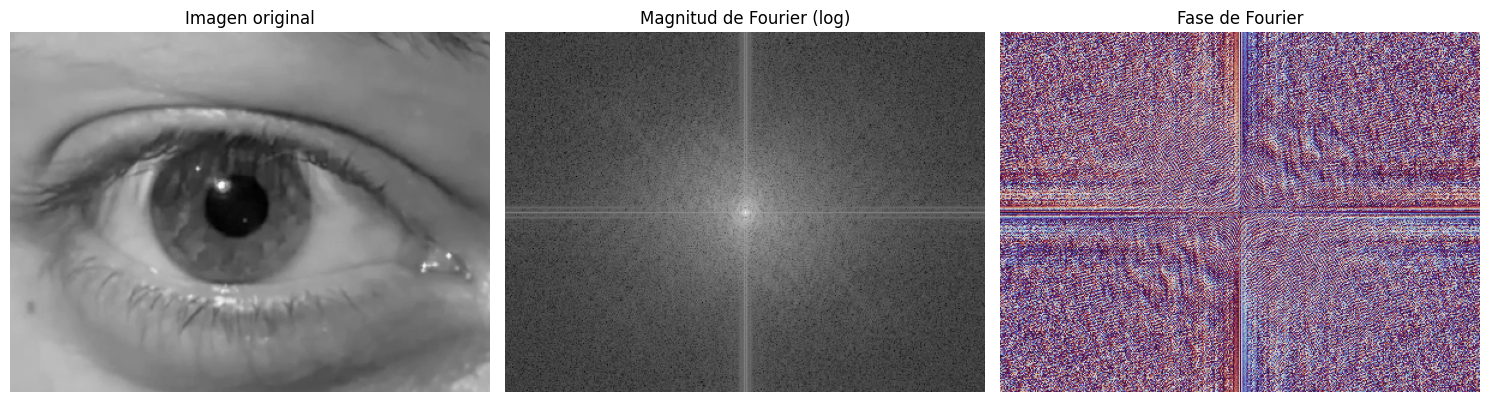

In [38]:
# Imagen original
img = roi_gris.astype(np.float32)

# Transformada de Fourier 2D
F = np.fft.fft2(img)

# Centrar las frecuencias bajas
F_shift = np.fft.fftshift(F)

# Magnitud y fase
magnitud = np.abs(F_shift)
fase = np.angle(F_shift)

# Escala logarítmica para visualizar la magnitud
magnitud_log = np.log1p(magnitud)

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Imagen original")

axes[1].imshow(magnitud_log, cmap="gray")
axes[1].set_title("Magnitud de Fourier (log)")

axes[2].imshow(fase, cmap="twilight", vmin=-np.pi, vmax=np.pi)
axes[2].set_title("Fase de Fourier")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

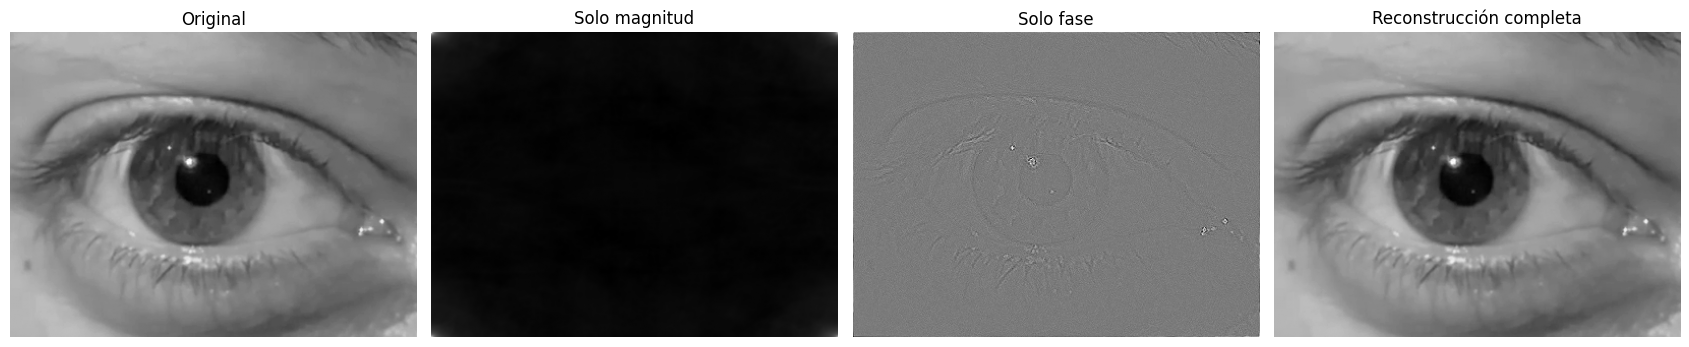

Error máximo de reconstrucción: 0.00005341


In [39]:
# Reconstrucción de la imagen desde Fourier

# Magnitud y fase originales (sin shift)
magnitud_original = np.abs(F)
fase_original = np.angle(F)

# Reconstrucción con solo magnitud
F_solo_magnitud = magnitud_original * np.exp(1j * 0)

img_magnitud = np.real(
    np.fft.ifft2(F_solo_magnitud)
)

# Reconstrucción con solo fase
F_solo_fase = np.exp(1j * fase_original)

img_fase = np.real(
    np.fft.ifft2(F_solo_fase)
)

# Reconstrucción completa
img_reconstruida = np.real(
    np.fft.ifft2(F)
)

# Normalización para visualización
def normalizar(img):
    return cv2.normalize(
        img, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

imagenes = [
    img,
    img_magnitud,
    img_fase,
    img_reconstruida
]

titulos = [
    "Original",
    "Solo magnitud",
    "Solo fase",
    "Reconstrucción completa"
]

fig, axes = plt.subplots(1, 4, figsize=(17, 5))

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(normalizar(imagen), cmap="gray")
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Error de reconstrucción completa
error = np.max(np.abs(img - img_reconstruida))

print(f"Error máximo de reconstrucción: {error:.8f}")

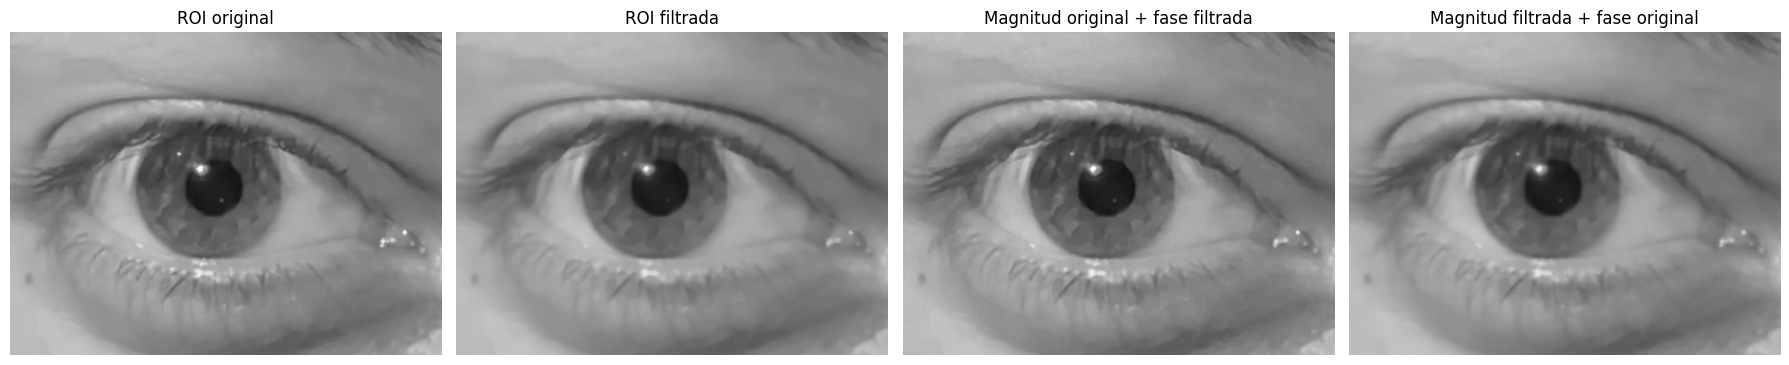

In [41]:
# Intercambio de magnitud y fase entre imágenes

# Imagen 1: ROI original
img1 = roi_gris.astype(np.float32)

# Imagen 2: ROI filtrada con mediana
img2 = cv2.medianBlur(roi_gris, 5).astype(np.float32)

# Transformadas de Fourier
F1 = np.fft.fft2(img1)
F2 = np.fft.fft2(img2)

# Magnitudes y fases
M1 = np.abs(F1)
M2 = np.abs(F2)

P1 = np.angle(F1)
P2 = np.angle(F2)

# Magnitud original + fase filtrada
F_cruzada_1 = M1 * np.exp(1j * P2)
img_cruzada_1 = np.real(np.fft.ifft2(F_cruzada_1))

# Magnitud filtrada + fase original
F_cruzada_2 = M2 * np.exp(1j * P1)
img_cruzada_2 = np.real(np.fft.ifft2(F_cruzada_2))

# Visualización
imagenes = [
    img1,
    img2,
    img_cruzada_1,
    img_cruzada_2
]

titulos = [
    "ROI original",
    "ROI filtrada",
    "Magnitud original + fase filtrada",
    "Magnitud filtrada + fase original"
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

La magnitud del espectro (en escala logarítmica) concentra la mayor parte de la energía en el centro, es decir, en las frecuencias bajas: la imagen está dominada por variaciones suaves de intensidad (piel, esclerótica, iris). La energía disminuye hacia los bordes del espectro, que corresponden a los detalles finos (bordes de la pupila, pestañas, textura del iris). Se observa además una cruz brillante en los ejes horizontal y vertical, producida por la discontinuidad entre los bordes opuestos de la imagen, ya que la TFD-2D la trata como si se repitiera periódicamente. La fase, en cambio, no muestra una estructura interpretable a simple vista.

La reconstrucción completa, a partir de magnitud y fase, reproduce la imagen original con un error máximo del orden de 10⁻⁵ niveles de gris, atribuible al redondeo numérico. Por lo tanto, la TFD-2D es reversible y no pierde información.

La reconstrucción con solo magnitud (fase igual a cero) no conserva ninguna estructura reconocible: toda la energía se concentra en un único punto y, al normalizar para visualizar, el resto de la imagen queda prácticamente negro. La reconstrucción con solo fase (magnitud igual a uno), en cambio, conserva los contornos del ojo: se distinguen el borde de la pupila, el iris, los párpados y los reflejos corneales, aunque se pierden las intensidades y los niveles de gris.

Al combinar la magnitud de la ROI original con la fase de la ROI filtrada (y viceversa), ambas imágenes resultantes conservan la estructura completa del ojo. Como la imagen filtrada con mediana es muy similar a la original, las diferencias entre las combinaciones son sutiles.

En conclusión, la fase es la que conserva la información estructural de la imagen: codifica la posición de los bordes y contornos. La magnitud indica cuánta energía hay en cada frecuencia, pero no dónde se ubica en la imagen.

### Densidad Espectral de Potencia (PSD)

La PSD permite analizar cómo se distribuye la potencia de una imagen entre sus diferentes frecuencias espaciales.

Se calcula a partir de la Transformada de Fourier 2D:

$$PSD(u,v)=|F(u,v)|^2$$

Donde $F(u,v)$ es la transformada de Fourier de la imagen.
- Frecuencias bajas: representan variaciones suaves de intensidad, como regiones relativamente uniformes de la piel o el iris.
- Frecuencias altas: representan cambios rápidos de intensidad, como bordes, detalles finos y ruido.
Al aplicar un filtro espacial suavizante, esperamos observar una reducción de la potencia asociada a las frecuencias altas.

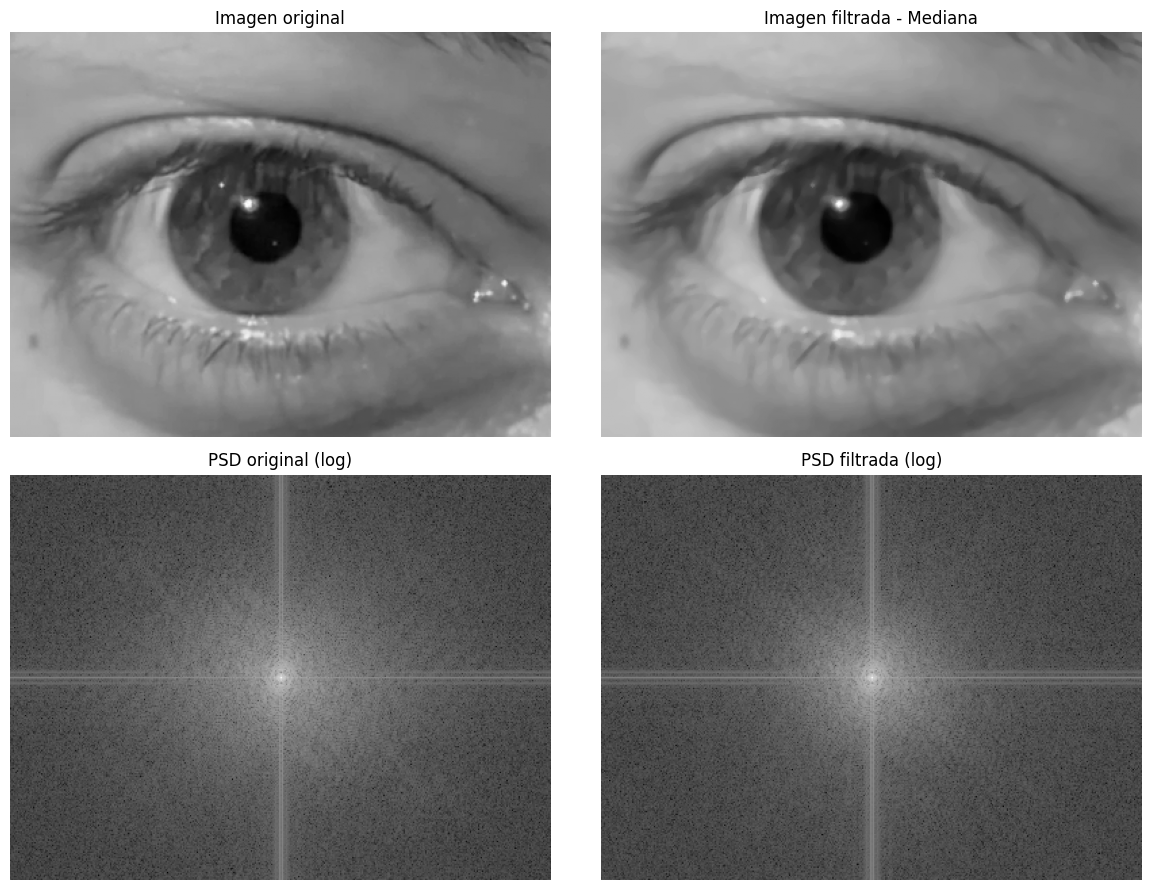

In [43]:
# Imagen original y filtrada
img_original = roi_gris.astype(np.float32)
img_filtrada = cv2.medianBlur(roi_gris, 5).astype(np.float32)

# Transformada de Fourier 2D
F_original = np.fft.fftshift(np.fft.fft2(img_original))
F_filtrada = np.fft.fftshift(np.fft.fft2(img_filtrada))

# PSD = Magnitud al cuadrado
PSD_original = np.abs(F_original)**2
PSD_filtrada = np.abs(F_filtrada)**2

# Escala logarítmica para visualización
PSD_original_log = np.log1p(PSD_original)
PSD_filtrada_log = np.log1p(PSD_filtrada)

# Escala común para comparar ambas PSD
vmin = min(PSD_original_log.min(), PSD_filtrada_log.min())
vmax = max(PSD_original_log.max(), PSD_filtrada_log.max())

# Visualización
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].imshow(img_original, cmap="gray")
axes[0, 0].set_title("Imagen original")

axes[0, 1].imshow(img_filtrada, cmap="gray")
axes[0, 1].set_title("Imagen filtrada - Mediana")

axes[1, 0].imshow(
    PSD_original_log, cmap="gray", vmin=vmin, vmax=vmax
)
axes[1, 0].set_title("PSD original (log)")

axes[1, 1].imshow(
    PSD_filtrada_log, cmap="gray", vmin=vmin, vmax=vmax
)
axes[1, 1].set_title("PSD filtrada (log)")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

En ambas PSD la potencia se concentra en el centro del espectro, es decir, en las frecuencias bajas, y disminuye progresivamente hacia los bordes. Esto confirma que la imagen está dominada por variaciones suaves de intensidad (piel, esclerótica, iris), mientras que los detalles finos (bordes, pestañas, textura del iris, ruido) aportan una fracción mucho menor de la potencia total. En las dos se observa también la cruz horizontal y vertical, debida a la discontinuidad entre los bordes opuestos de la imagen.

Al comparar la PSD original con la de la imagen filtrada con mediana 5×5, las diferencias son sutiles; la región central prácticamente no cambia, y la zona periférica (frecuencias altas) se ve levemente más oscura en la imagen filtrada. Esto es coherente con lo esperado para un filtro suavizante que atenúa las frecuencias altas y conserva las bajas.

La diferencia es pequeña porque la mediana es un filtro no lineal que elimina principalmente valores aislados y detalles muy finos, pero preserva los bordes grandes, como el contorno de la pupila y del iris. Además, al estar representada en escala logarítmica, la PSD comprime las diferencias de potencia, lo que hace que una reducción real de las altas frecuencias se perciba poco a simple vista.

### Filtrado en frecuencia
 
El filtrado frecuencial consiste en modificar las componentes de frecuencia espacial de una imagen mediante una máscara \(H(u,v)\):

$$G(u,v)=F(u,v)\cdot H(u,v)$$

Donde:
- $F(u,v)$: Transformada de Fourier de la imagen original.
- $H(u,v)$: función de transferencia del filtro.
- $G(u,v)$: espectro de la imagen filtrada.
Utilizaremos filtros ideales:
- Pasa-bajos: conserva las frecuencias bajas y elimina las superiores a una frecuencia de corte.
- Pasa-altos: conserva las frecuencias altas y elimina las inferiores a la frecuencia de corte.

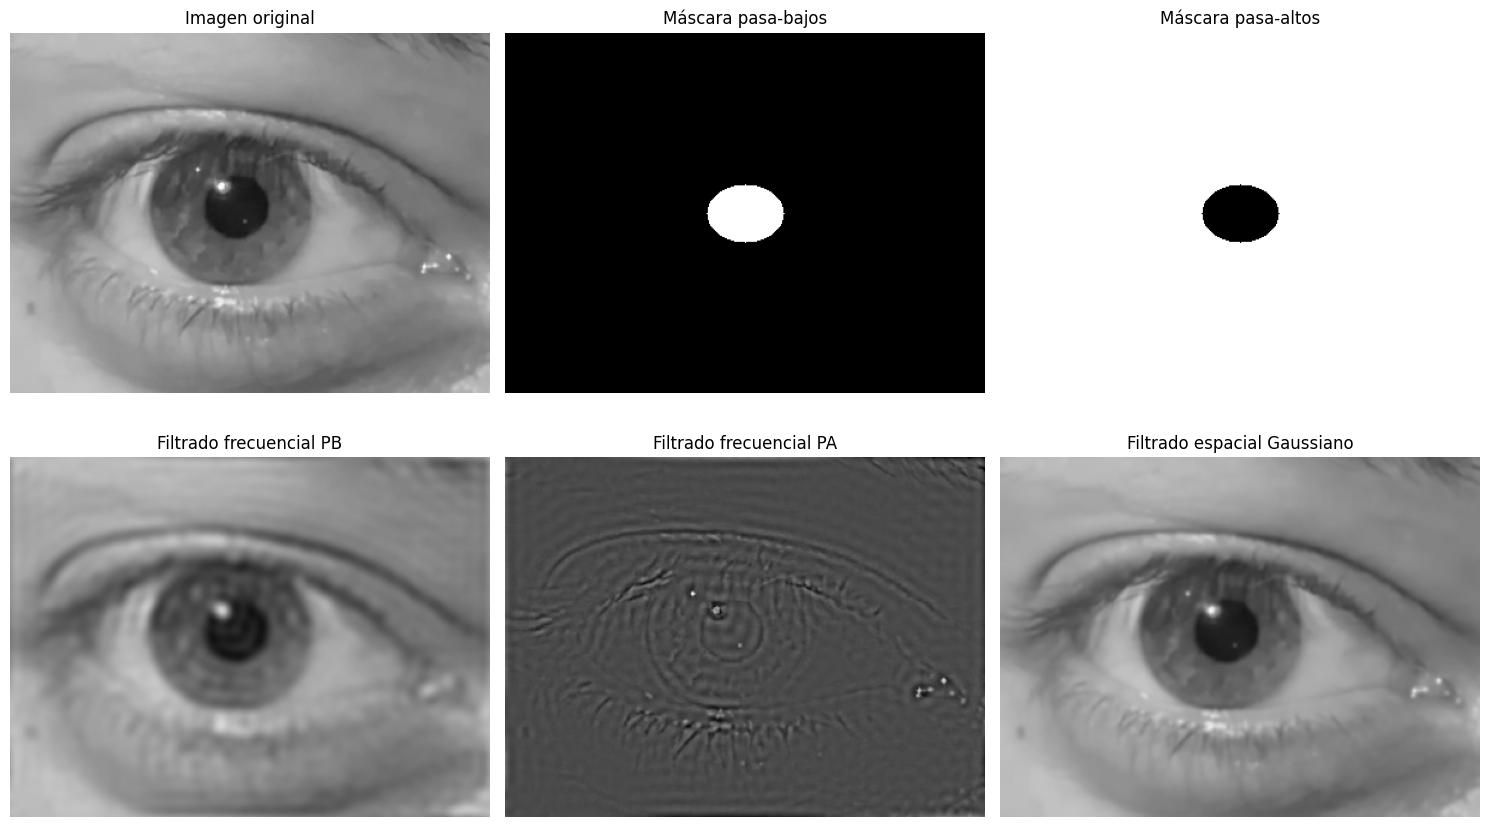

In [44]:
# Imagen original
img = roi_gris.astype(np.float32)

# Transformada de Fourier 2D
F = np.fft.fftshift(np.fft.fft2(img))

# Dimensiones
alto, ancho = img.shape

# Coordenadas de frecuencia
fy = np.fft.fftshift(np.fft.fftfreq(alto))
fx = np.fft.fftshift(np.fft.fftfreq(ancho))

FX, FY = np.meshgrid(fx, fy)

# Distancia al centro del espectro
D = np.sqrt(FX**2 + FY**2)

# Frecuencia de corte (ciclos/píxel)
D0 = 0.08

# Filtro pasa-bajos ideal
H_PB = (D <= D0).astype(float)

# Filtro pasa-altos ideal
H_PA = (D > D0).astype(float)

# Aplicación de los filtros en frecuencia
F_PB = F * H_PB
F_PA = F * H_PA

# Reconstrucción mediante Transformada Inversa
img_PB = np.real(
    np.fft.ifft2(np.fft.ifftshift(F_PB))
)

img_PA = np.real(
    np.fft.ifft2(np.fft.ifftshift(F_PA))
)

# Filtrado espacial para comparar
img_espacial = cv2.GaussianBlur(
    roi_gris, (5, 5), 1
)

# Visualización
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Imagen original")

axes[0, 1].imshow(H_PB, cmap="gray")
axes[0, 1].set_title("Máscara pasa-bajos")

axes[0, 2].imshow(H_PA, cmap="gray")
axes[0, 2].set_title("Máscara pasa-altos")

axes[1, 0].imshow(img_PB, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Filtrado frecuencial PB")

axes[1, 1].imshow(img_PA, cmap="gray")
axes[1, 1].set_title("Filtrado frecuencial PA")

axes[1, 2].imshow(img_espacial, cmap="gray", vmin=0, vmax=255)
axes[1, 2].set_title("Filtrado espacial Gaussiano")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

1. ¿Qué filtro preserva mejor los bordes de la pupila eliminando los destellos/reflejos del flash?

De los filtros evaluados, el filtro de mediana es una buena alternativa para reducir ruido impulsivo y preservar los bordes de la pupila, ya que reemplaza cada píxel por la mediana de su vecindario, sin promediar directamente intensidades como el filtro de media.

Sin embargo, hay una distinción importante:
- Filtro de mediana: reduce ruido impulsivo y puede atenuar reflejos pequeños y aislados, conservando relativamente bien los bordes.
- Filtro Gaussiano: suaviza el ruido, pero también difumina el límite entre la pupila y el iris.
- Filtro pasa-bajos: reduce las altas frecuencias, pero puede eliminar detalles importantes del contorno pupilar.
- Filtro pasa-altos: resalta bordes, pero también enfatiza los bordes de los reflejos.
Conclusión: entre los filtros implementados, elegiríamos inicialmente la mediana para preservar el contorno pupilar. No obstante, los reflejos intensos del flash pueden ocupar regiones extensas y no eliminarse mediante estos filtros. Para corregirlos específicamente, podría ser necesario detectarlos mediante un umbral de intensidad y aplicar técnicas de reconstrucción (inpainting).
2. ¿Cómo cuantificar la calidad de una imagen comparándola con la original?
Utilizamos dos métricas:

PSNR (Peak Signal-to-Noise Ratio): mide la diferencia entre dos imágenes a partir del error cuadrático medio (MSE).
$$PSNR=10\log_{10}\left(\frac{MAX^2}{MSE}\right)$$

Cuanto mayor es el PSNR, menor es el error respecto de la imagen de referencia.

SSIM (Structural Similarity Index): evalúa la similitud estructural considerando luminancia, contraste y estructura. Un SSIM de 1 indica imágenes idénticas.

Ambas métricas miden fidelidad respecto de una referencia, no necesariamente la capacidad de eliminar reflejos. Una imagen sin procesar tendrá PSNR infinito y SSIM igual a 1 al compararse consigo misma.

In [45]:
# Imagen de referencia
referencia = roi_gris.astype(np.uint8)

# Función para convertir imágenes al rango [0, 255]
def convertir_uint8(imagen):
    return np.clip(imagen, 0, 255).astype(np.uint8)

# Imágenes a comparar
imagenes_filtradas = {
    "Media 5x5": cv2.blur(referencia, (5, 5)),
    "Mediana 5x5": cv2.medianBlur(referencia, 5),
    "Gaussiano 5x5": cv2.GaussianBlur(referencia, (5, 5), 1),
    "Pasa-bajos frecuencial": convertir_uint8(img_PB),
    "Pasa-altos frecuencial": convertir_uint8(img_PA)
}

# Cálculo de métricas
resultados = []

for nombre, imagen in imagenes_filtradas.items():

    psnr = peak_signal_noise_ratio(
        referencia, imagen, data_range=255
    )

    ssim = structural_similarity(
        referencia, imagen, data_range=255
    )

    resultados.append({
        "Filtro": nombre,
        "PSNR (dB)": round(psnr, 2),
        "SSIM": round(ssim, 4)
    })

# Tabla de resultados
df_metricas = pd.DataFrame(resultados)

display(df_metricas.sort_values(
    by="SSIM", ascending=False
))

,Filtro,PSNR (dB),SSIM
2,Gaussiano 5x5,44.32,0.9895
1,Mediana 5x5,41.02,0.9800
0,Media 5x5,39.54,0.9716
3,Pasa-bajos frecuencial,33.68,0.8949
4,Pasa-altos frecuencial,5.30,0.0155


Se compararon los resultados de los filtros espaciales y frecuenciales utilizando las métricas PSNR y SSIM, tomando la ROI original como referencia.

El filtro Gaussiano 5×5 presentó los mayores valores de PSNR (44.32 dB) y SSIM (0.9895), indicando que fue el que mejor conservó la información de la imagen original. Le siguió el filtro de mediana 5×5, con un PSNR de 41.02 dB y un SSIM de 0.9800.

El filtrado pasa-bajos frecuencial produjo una mayor modificación de la imagen, mientras que el pasa-altos presentó valores considerablemente menores, debido a que elimina las componentes de baja frecuencia y conserva principalmente las variaciones rápidas de intensidad.

Si bien el filtro Gaussiano presentó la mayor fidelidad respecto de la imagen original, el filtro de mediana puede resultar más adecuado para atenuar ruido impulsivo preservando los bordes pupilares.

Finalmente, se destaca que PSNR y SSIM permiten cuantificar la similitud respecto de una imagen de referencia, pero no determinan por sí solos la eficacia en la eliminación de reflejos especulares. Para ello, es necesario complementar estas métricas con una evaluación visual del contorno pupilar y los artefactos presentes.